![Logo](https://github.com/Columbia-Neuropythonistas/IntroPythonForNeuroscientists2023/assets/65978061/138766b5-ac36-4dc8-b9d4-bf512ecebe78)

# **Week 9: Machine learning and navigating codebases**

In [1]:
#remember that when we use 'as', we are simply telling Python what term we want to refer to our imported packages by
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


## Problem 1: Finding the dataset

We are going to analyse data collected in [High-dimensional geometry of population responses in visual cortex](https://www.nature.com/articles/s41586-019-1346-5).

1. Try to find where the data is available (hint: Nature and many other journals have a "Data availability" section).
2. There are many different files stored in the repository. We want to download the data recorded in mouse "M170717" on August 25, 2017. To figure out how the files are stored, consult the instructions on [Github repository](https://github.com/MouseLand/stringer-pachitariu-et-al-2018b). (**Important:** Make sure you download the neural recordings, not the stimulus set!)

## Getting to know the dataset

I've already prepared a numpy array containing the specific responses. Below we're loading it into the notebook:

In [2]:
recording = np.load("/home/utkuf/gitrepos/IntroPythonForNeuroscientists2026/Week07/recording.npy")

How is this array structured?

In [3]:
recording.shape

(480, 11523)

It contains the responses of 11,523 neurons to 480 stimuli.

## Problem 2

To get some idea of the data, let's plot a histogram of the first neuron's responses across all presented images. At this point, we just quickly want to get an idea for the format of the data. Since it is a numpy array, matplotlib is perfect for this.

(array([362.,  68.,  28.,   4.,   7.,   4.,   3.,   3.,   0.,   1.]),
 array([ 0.        ,  7.51619577, 15.03239155, 22.5485878 , 30.0647831 ,
        37.58097839, 45.0971756 , 52.61336899, 60.12956619, 67.64575958,
        75.16195679]),
 <BarContainer object of 10 artists>)

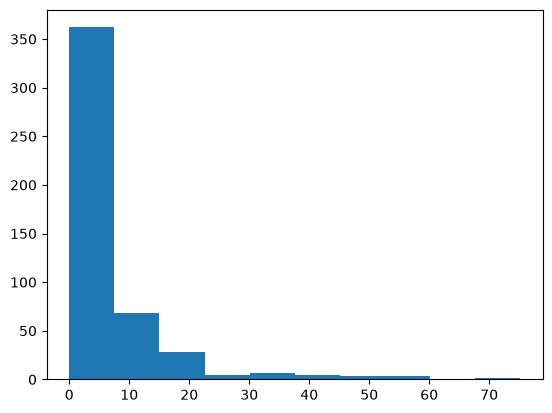

In [4]:
plt.hist(recording[:,0])

This data is extremely high-dimensional and so it is difficult to get a good idea of structures within this data simply from examining it. **Machine learning** makes this general problem tractable.

## Introduction to Machine learning

In science, we routinely break a vague question ("How does the brain represent orientation?") down into more specific components ("How do neurons in visual cortex respond to oriented gratings?") and then settle on a particular methodology to answer the concrete questions (e.g. record calcium traces using 2-photon imaging).

Machine learning is no different. In our case, our vague question is "What is the structure of our data?". One concrete way of asking this question is to ask about lower-dimensional structures. Our brain does this automatically all the time! In fact, consider oriented gratings:

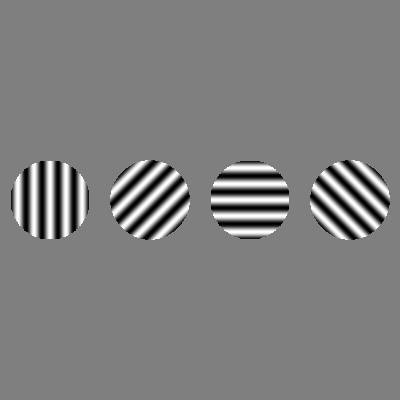

This is an extremely high-dimensional stimulus with many different pixels (i.e. dimensions). However, we break it down into a few factors of variation, e.g. orientation and frequency. Methods to uncover such underlying factors of variation are called **dimensionality reduction**.

We therefore operationalize "What is the structure of the data?" by looking at dimensionality reduction. There are many different possible ways of performing dimensionality reduction. One important such method is **Principal Component Analysis (PCA)**.

Below is a simple example:

In [5]:
x = np.random.multivariate_normal(mean=np.array([0., 0.]), cov=np.array([[1., 0.9], [0.9, 1.]]), size=(100,))

This data is two-dimensional:

In [6]:
x.shape

(100, 2)

If we look at each dimension, we don't really understand how the different variables are related:

(array([ 1.,  8.,  8., 22., 18., 23., 10.,  6.,  2.,  2.]),
 array([-2.95615358, -2.35152166, -1.74688973, -1.1422578 , -0.53762587,
         0.06700605,  0.67163798,  1.27626991,  1.88090184,  2.48553377,
         3.09016569]),
 <BarContainer object of 10 artists>)

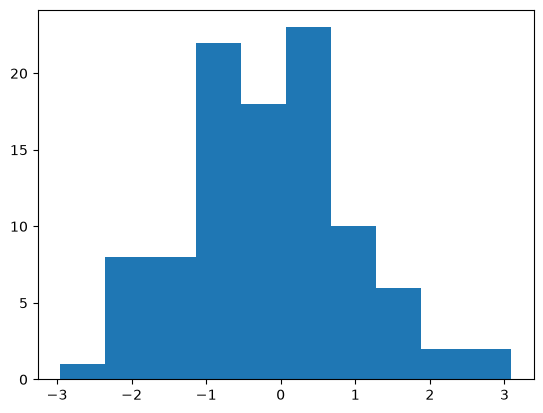

In [7]:
plt.hist(x[:,0])

(array([ 1.,  2.,  4., 17., 18., 16., 24., 11.,  4.,  3.]),
 array([-3.51746883, -2.89685598, -2.27624313, -1.65563028, -1.03501743,
        -0.41440457,  0.20620828,  0.82682113,  1.44743398,  2.06804683,
         2.68865968]),
 <BarContainer object of 10 artists>)

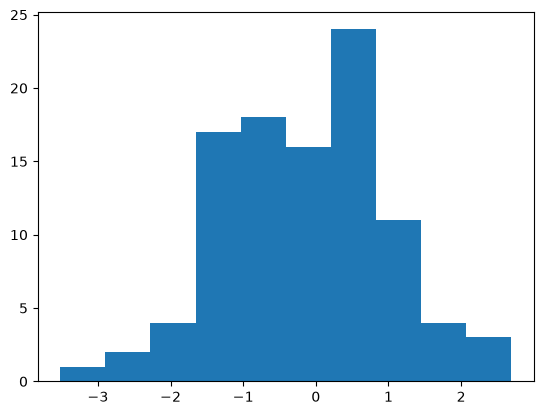

In [8]:
plt.hist(x[:,1])

However, if we plot a scatter plot, we can see some dominant components:

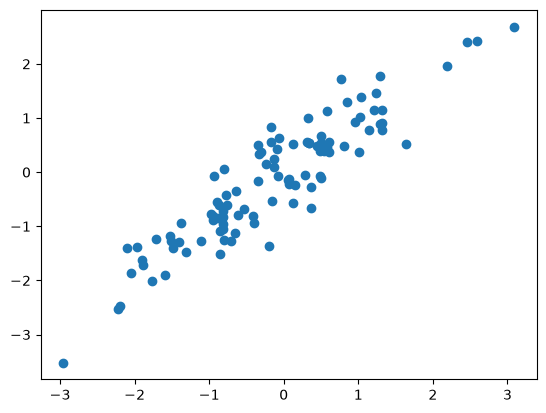

In [9]:
plt.scatter(x[:,0], x[:,1])

With two dimensions, we can do this by visual inspection. For higher-dimensional data, we need to use PCA.

How can we implement PCA in Python? To find out how a particular method is implemented in Python, we simply google it.

## Problem 3

Compute a PCA that extracts the first ten components from the neural recordings.

**Hint 1:** **Copy the code** in the examples and figure out what part of it to modify.

**Hint 2:** You often need to make sure that the data is in the format your machine learning algorithm expects. In this case, the different images are the samples and the different neurons the variables. Make sure that your data is formatted correctly!

**Hint 3:** The examples don't explain how to extract the components, just how to fit the model. Look through the attributes to identify how you get these components.

In [10]:
# Fit the PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=20, whiten=True)
pca.fit(recording.T)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",20
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",True
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized SVD 

In [11]:
# Extract the PCA
pca.components_[:10]

array([[ 0.03010092,  0.03847994,  0.05845146, ...,  0.02709745,
         0.0067198 ,  0.02983106],
       [ 0.0158404 ,  0.0068024 ,  0.00114371, ..., -0.00566428,
         0.00050414,  0.06521222],
       [-0.04802123, -0.05043424, -0.03799358, ..., -0.0105623 ,
         0.0008104 ,  0.02343223],
       ...,
       [ 0.03990796, -0.03772677,  0.01027626, ..., -0.00165856,
        -0.01692661,  0.01703633],
       [ 0.05600587,  0.07120628, -0.06443314, ...,  0.00926078,
         0.00145989,  0.03564069],
       [ 0.05211323,  0.00411127,  0.08278015, ...,  0.01834419,
         0.00637577,  0.00760195]], shape=(10, 480), dtype=float32)

## Plot components

Now, let's create some plots of these components! To do so, we want to use seaborn, which uses dataframes. We therefore transform our array of components into a dataframe.

In [12]:
from sklearn.decomposition import PCA
pca = PCA(n_components=20, whiten=True)
pca.fit(recording.T)
components = pca.components_
df_components = pd.DataFrame(components.T)

In [13]:
df_components

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,0.030101,0.015840,-0.048021,-0.024839,-0.080392,0.048464,0.009867,0.039908,0.056006,0.052113,0.058829,-0.016003,-0.069502,-0.005474,-0.012063,0.021463,0.001501,0.053896,-0.017089,-0.012694
1,0.038480,0.006802,-0.050434,0.048128,0.001429,0.096598,0.079098,-0.037727,0.071206,0.004111,-0.036642,-0.054151,0.007870,0.028353,-0.026970,-0.033519,0.047704,0.040572,-0.033749,0.035580
2,0.058451,0.001144,-0.037994,-0.060235,0.068519,0.146991,0.084102,0.010276,-0.064433,0.082780,0.037852,0.027907,0.138787,0.002071,0.034540,0.044502,0.075174,0.118147,-0.109411,-0.058658
3,0.045857,0.117573,0.056693,0.012179,-0.017930,0.020666,0.063065,0.073037,-0.029741,0.017761,0.053164,-0.020832,-0.035950,0.206706,0.026060,0.041209,-0.057018,0.022330,-0.091737,-0.135758
4,0.059655,-0.052693,0.067922,-0.004119,-0.046574,0.084171,0.070590,-0.082794,-0.002447,0.010063,0.026091,-0.008146,0.036346,-0.081149,0.073481,0.170842,0.077831,0.004937,0.095624,0.026696
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.018063,0.009878,-0.014739,-0.036785,-0.018146,-0.045170,0.025054,-0.020140,-0.019108,-0.022484,-0.024734,0.004369,0.014018,0.005153,-0.005798,-0.020624,0.025821,0.019403,-0.015595,0.002294
476,0.035360,-0.035641,0.038032,0.000924,0.005202,-0.032945,0.006262,-0.011237,0.030784,0.013152,0.038942,0.024355,-0.019776,-0.018936,0.099626,-0.012786,0.003845,-0.038179,-0.003687,0.024110
477,0.027097,-0.005664,-0.010562,0.024096,0.014612,-0.014500,0.000228,-0.001659,0.009261,0.018344,0.007191,0.006815,-0.009456,-0.023809,0.016735,0.021747,0.017825,-0.022805,-0.010361,-0.012843
478,0.006720,0.000504,0.000810,-0.008482,0.000406,-0.001621,-0.004694,-0.016927,0.001460,0.006376,-0.005377,-0.015946,0.009900,0.005999,-0.007910,0.000253,0.022656,0.027523,-0.006477,-0.002097


In [14]:
df_components = df_components.add_prefix('comp_')

In [15]:
df_components

,comp_0,comp_1,comp_2,comp_3,comp_4,comp_5,comp_6,comp_7,comp_8,comp_9,comp_10,comp_11,comp_12,comp_13,comp_14,comp_15,comp_16,comp_17,comp_18,comp_19
0,0.030101,0.015840,-0.048021,-0.024839,-0.080392,0.048464,0.009867,0.039908,0.056006,0.052113,0.058829,-0.016003,-0.069502,-0.005474,-0.012063,0.021463,0.001501,0.053896,-0.017089,-0.012694
1,0.038480,0.006802,-0.050434,0.048128,0.001429,0.096598,0.079098,-0.037727,0.071206,0.004111,-0.036642,-0.054151,0.007870,0.028353,-0.026970,-0.033519,0.047704,0.040572,-0.033749,0.035580
2,0.058451,0.001144,-0.037994,-0.060235,0.068519,0.146991,0.084102,0.010276,-0.064433,0.082780,0.037852,0.027907,0.138787,0.002071,0.034540,0.044502,0.075174,0.118147,-0.109411,-0.058658
3,0.045857,0.117573,0.056693,0.012179,-0.017930,0.020666,0.063065,0.073037,-0.029741,0.017761,0.053164,-0.020832,-0.035950,0.206706,0.026060,0.041209,-0.057018,0.022330,-0.091737,-0.135758
4,0.059655,-0.052693,0.067922,-0.004119,-0.046574,0.084171,0.070590,-0.082794,-0.002447,0.010063,0.026091,-0.008146,0.036346,-0.081149,0.073481,0.170842,0.077831,0.004937,0.095624,0.026696
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.018063,0.009878,-0.014739,-0.036785,-0.018146,-0.045170,0.025054,-0.020140,-0.019108,-0.022484,-0.024734,0.004369,0.014018,0.005153,-0.005798,-0.020624,0.025821,0.019403,-0.015595,0.002294
476,0.035360,-0.035641,0.038032,0.000924,0.005202,-0.032945,0.006262,-0.011237,0.030784,0.013152,0.038942,0.024355,-0.019776,-0.018936,0.099626,-0.012786,0.003845,-0.038179,-0.003687,0.024110
477,0.027097,-0.005664,-0.010562,0.024096,0.014612,-0.014500,0.000228,-0.001659,0.009261,0.018344,0.007191,0.006815,-0.009456,-0.023809,0.016735,0.021747,0.017825,-0.022805,-0.010361,-0.012843
478,0.006720,0.000504,0.000810,-0.008482,0.000406,-0.001621,-0.004694,-0.016927,0.001460,0.006376,-0.005377,-0.015946,0.009900,0.005999,-0.007910,0.000253,0.022656,0.027523,-0.006477,-0.002097


<Axes: xlabel='comp_1', ylabel='comp_0'>

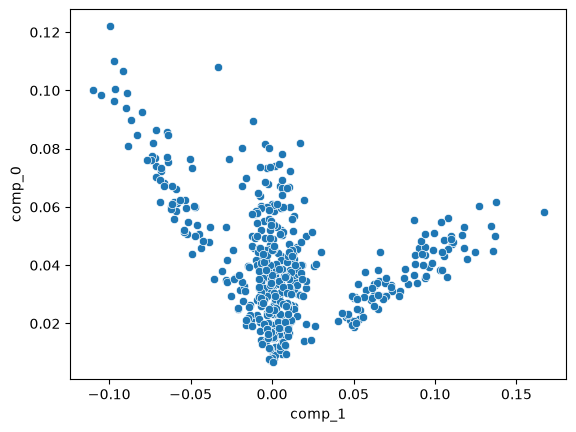

In [16]:
sns.scatterplot(data=df_components, x='comp_1', y='comp_0')

Let's make a PC scatterplot!

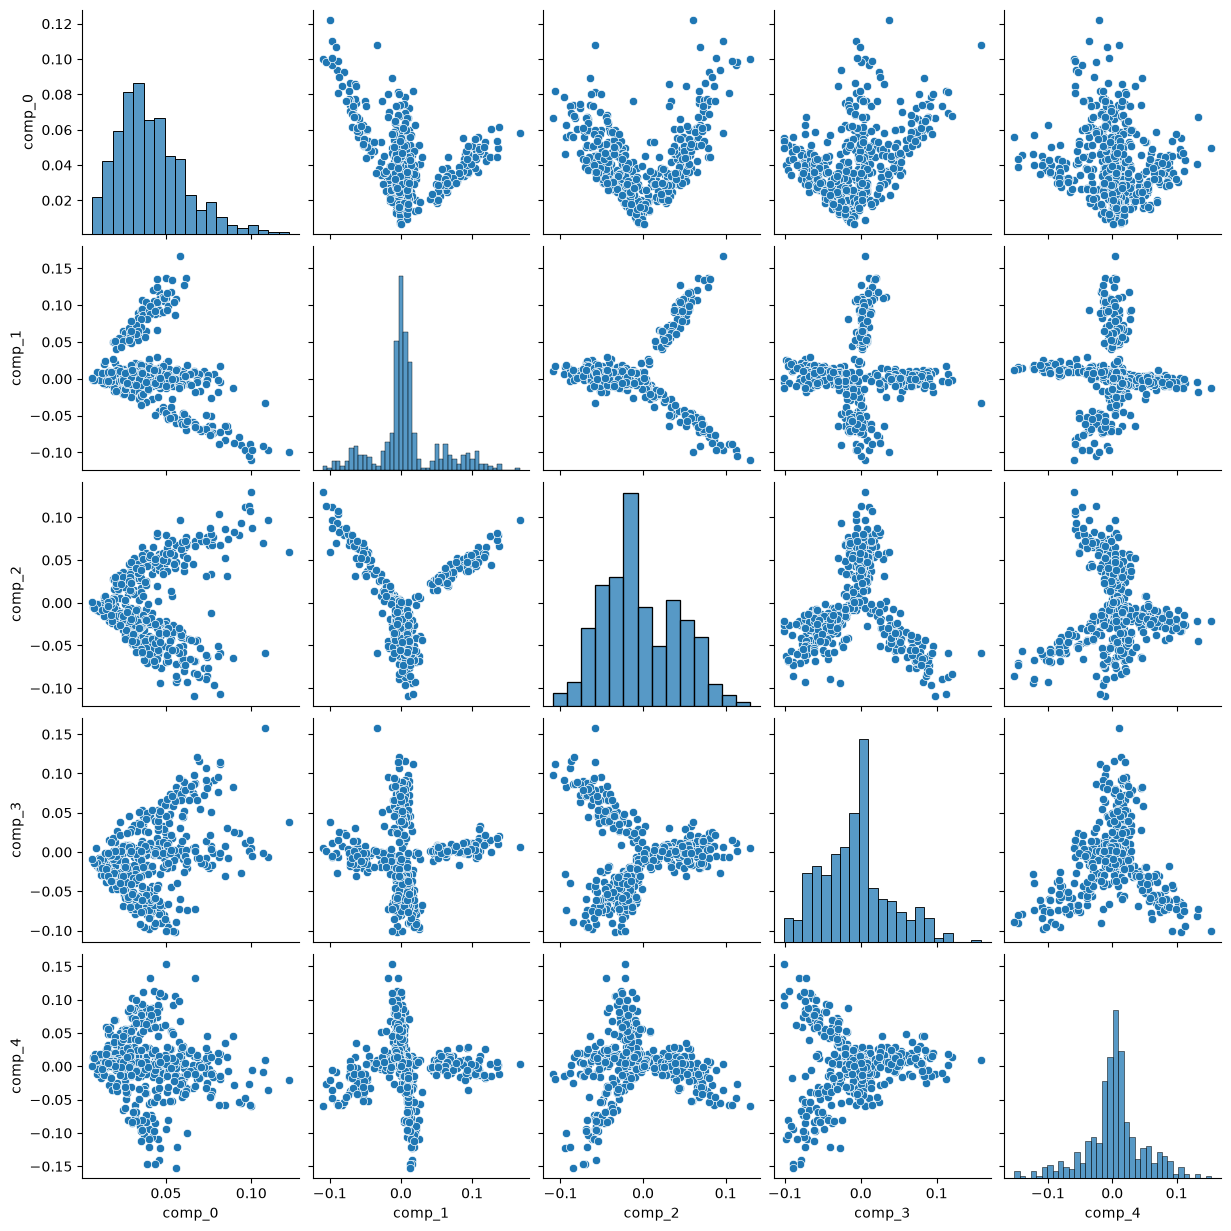

In [17]:
import seaborn as sns
sns.pairplot(df_components.iloc[:,:5])  # First five PCs
plt.show()

These are recordings of 5 different images! Let's see if they're represented differently.

In [18]:
img_index = np.load('img_index.npy')

In [19]:
img_index

array([1, 4, 3, 2, 5, 2, 1, 5, 3, 4, 4, 5, 1, 3, 2, 1, 3, 4, 5, 2, 4, 5,
       2, 1, 3, 1, 4, 5, 2, 3, 5, 4, 3, 2, 1, 1, 2, 3, 5, 4, 1, 4, 5, 3,
       2, 3, 4, 2, 5, 1, 3, 2, 4, 5, 1, 4, 5, 1, 3, 2, 5, 4, 1, 2, 3, 4,
       5, 3, 2, 1, 4, 1, 3, 2, 5, 2, 3, 1, 4, 5, 2, 3, 4, 1, 5, 1, 2, 3,
       5, 4, 2, 1, 3, 4, 5, 5, 4, 3, 1, 2, 5, 1, 2, 3, 4, 2, 3, 4, 1, 5,
       5, 2, 3, 1, 4, 2, 4, 3, 1, 5, 4, 1, 2, 5, 3, 3, 2, 4, 5, 1, 2, 5,
       4, 1, 3, 1, 2, 4, 5, 3, 4, 2, 5, 1, 3, 2, 5, 3, 4, 1, 5, 1, 2, 3,
       4, 1, 3, 2, 5, 4, 1, 5, 3, 2, 4, 5, 4, 1, 2, 3, 1, 3, 2, 5, 4, 5,
       3, 1, 4, 2, 1, 2, 4, 3, 5, 5, 3, 1, 4, 2, 4, 5, 3, 2, 1, 3, 5, 2,
       1, 4, 1, 5, 3, 2, 4, 1, 4, 2, 5, 3, 4, 3, 1, 2, 5, 2, 1, 3, 5, 4,
       5, 1, 2, 3, 4, 1, 2, 3, 5, 4, 4, 2, 5, 3, 1, 1, 4, 3, 5, 2, 5, 1,
       2, 3, 4, 1, 2, 5, 4, 3, 5, 4, 1, 3, 2, 5, 1, 3, 2, 4, 5, 4, 1, 2,
       3, 4, 2, 5, 1, 3, 2, 1, 5, 4, 3, 2, 3, 4, 1, 5, 5, 4, 2, 1, 3, 1,
       2, 3, 5, 4, 5, 1, 2, 3, 4, 4, 2, 3, 5, 1, 2,

In [20]:
df_components['img_index'] = img_index.astype(str)

In [21]:
df_components

,comp_0,comp_1,comp_2,comp_3,comp_4,comp_5,comp_6,comp_7,comp_8,comp_9,...,comp_11,comp_12,comp_13,comp_14,comp_15,comp_16,comp_17,comp_18,comp_19,img_index
0,0.030101,0.015840,-0.048021,-0.024839,-0.080392,0.048464,0.009867,0.039908,0.056006,0.052113,...,-0.016003,-0.069502,-0.005474,-0.012063,0.021463,0.001501,0.053896,-0.017089,-0.012694,1
1,0.038480,0.006802,-0.050434,0.048128,0.001429,0.096598,0.079098,-0.037727,0.071206,0.004111,...,-0.054151,0.007870,0.028353,-0.026970,-0.033519,0.047704,0.040572,-0.033749,0.035580,4
2,0.058451,0.001144,-0.037994,-0.060235,0.068519,0.146991,0.084102,0.010276,-0.064433,0.082780,...,0.027907,0.138787,0.002071,0.034540,0.044502,0.075174,0.118147,-0.109411,-0.058658,3
3,0.045857,0.117573,0.056693,0.012179,-0.017930,0.020666,0.063065,0.073037,-0.029741,0.017761,...,-0.020832,-0.035950,0.206706,0.026060,0.041209,-0.057018,0.022330,-0.091737,-0.135758,2
4,0.059655,-0.052693,0.067922,-0.004119,-0.046574,0.084171,0.070590,-0.082794,-0.002447,0.010063,...,-0.008146,0.036346,-0.081149,0.073481,0.170842,0.077831,0.004937,0.095624,0.026696,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
475,0.018063,0.009878,-0.014739,-0.036785,-0.018146,-0.045170,0.025054,-0.020140,-0.019108,-0.022484,...,0.004369,0.014018,0.005153,-0.005798,-0.020624,0.025821,0.019403,-0.015595,0.002294,1
476,0.035360,-0.035641,0.038032,0.000924,0.005202,-0.032945,0.006262,-0.011237,0.030784,0.013152,...,0.024355,-0.019776,-0.018936,0.099626,-0.012786,0.003845,-0.038179,-0.003687,0.024110,5
477,0.027097,-0.005664,-0.010562,0.024096,0.014612,-0.014500,0.000228,-0.001659,0.009261,0.018344,...,0.006815,-0.009456,-0.023809,0.016735,0.021747,0.017825,-0.022805,-0.010361,-0.012843,4
478,0.006720,0.000504,0.000810,-0.008482,0.000406,-0.001621,-0.004694,-0.016927,0.001460,0.006376,...,-0.015946,0.009900,0.005999,-0.007910,0.000253,0.022656,0.027523,-0.006477,-0.002097,3


<Axes: xlabel='comp_0', ylabel='comp_1'>

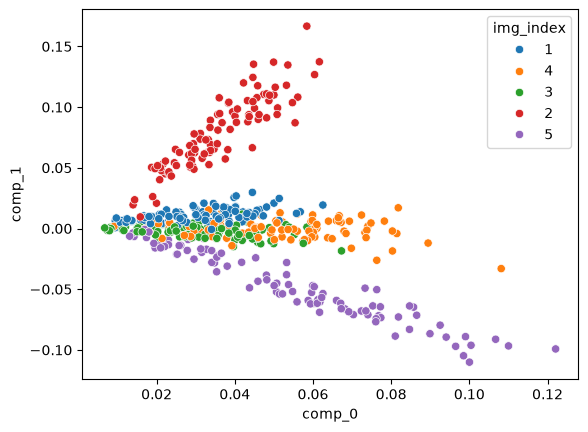

In [22]:
sns.scatterplot(data=df_components, x='comp_0', y='comp_1', hue='img_index')

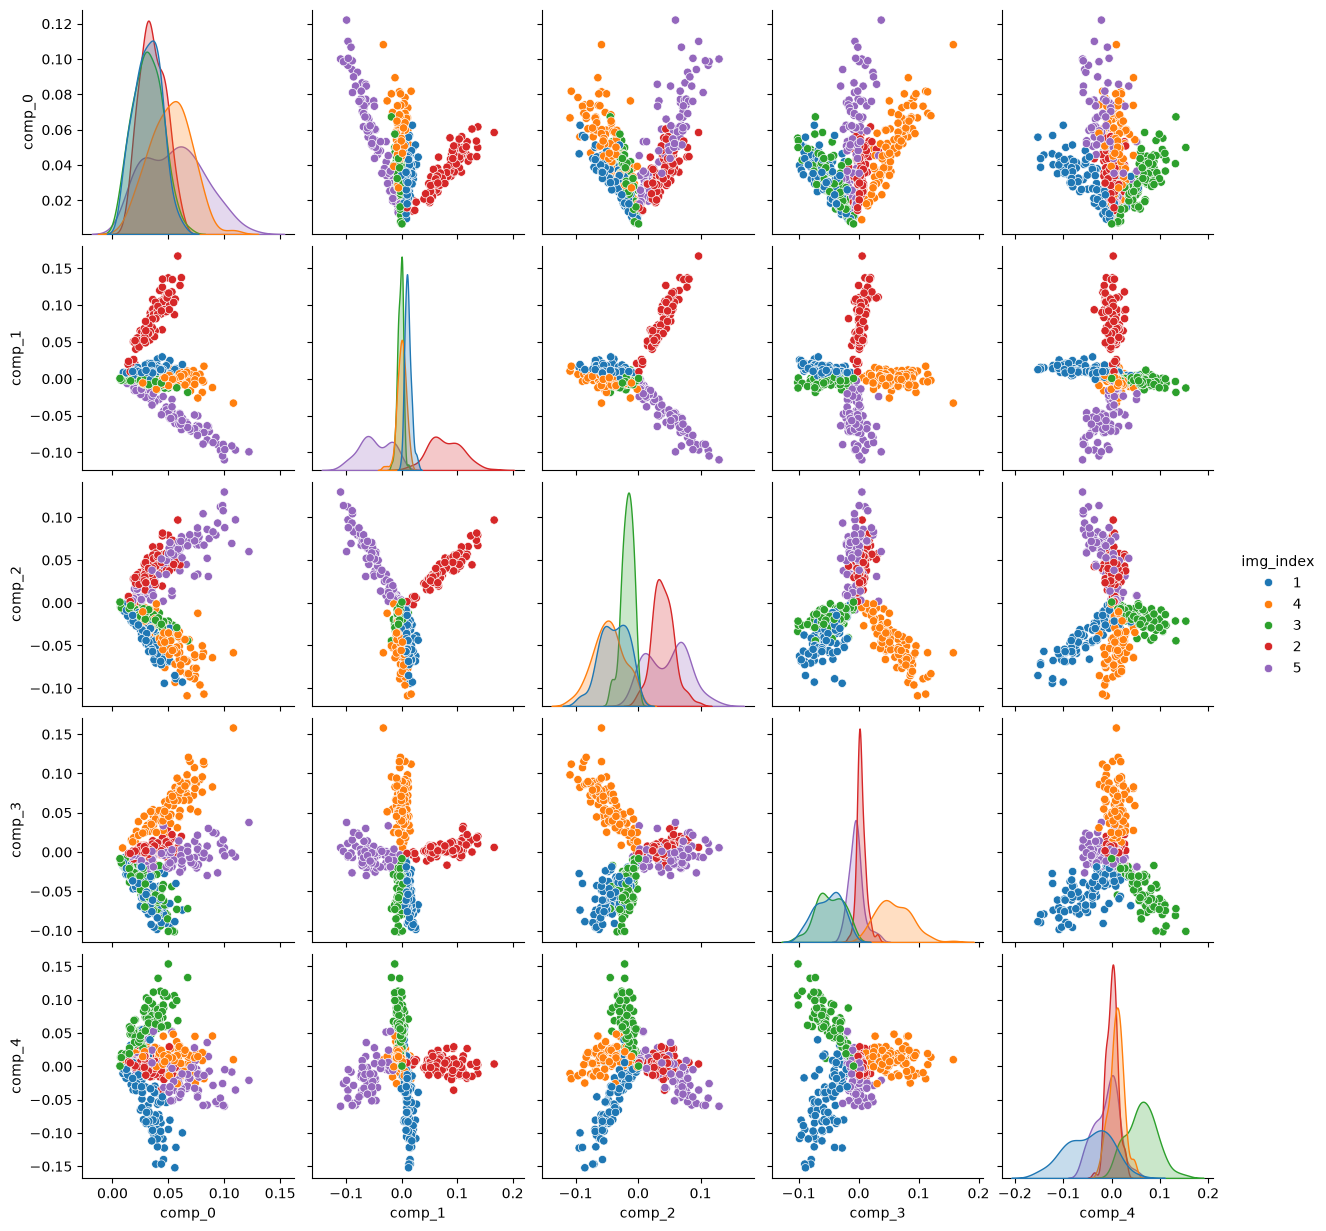

In [23]:
sns.pairplot(df_components.iloc[:, [0, 1, 2, 3, 4, -1]], hue='img_index')
plt.show()

## Support vector machines

How differently do the recordings represent repeated presentations of different images? One way of answering this question is by trying to predict which image each data point is representing.

<Axes: xlabel='comp_3', ylabel='comp_4'>

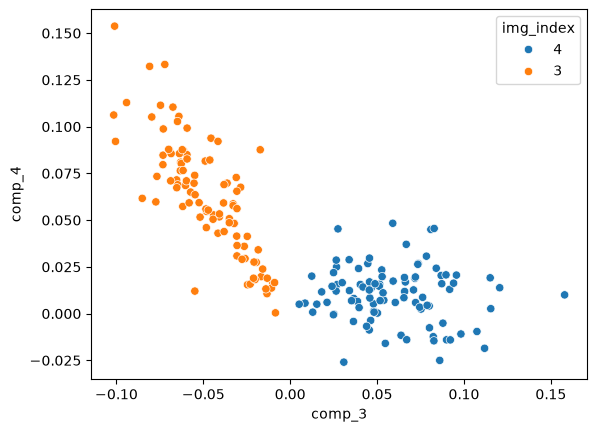

In [24]:
sns.scatterplot(data=df_components[np.isin(df_components['img_index'], ['3', '4'])], x='comp_3', y='comp_4', hue='img_index')

One method for doing so is a support vector machine, which tries to draw a line that separates the two classes.

## Problem 4: Support vector machine

Build a support vector machine that tries to predict whether a particular response represents image 1 or 2. Below we're extracting the responses to those two images:

In [25]:
components_subset = components[:,np.isin(df_components['img_index'], ['3', '4'])]
img_index_subset = df_components['img_index'][np.isin(df_components['img_index'], ['3', '4'])]

In [26]:
train_x = components_subset[:,:150]
train_y = img_index_subset[:150]
test_x = components_subset[:,150:]
test_y = img_index_subset[150:]

As before, try to find the help page for support vector machines. You should use the class `SVC` and use a linear kernel. Copy the relevant code and try to change the important parts to it. Again, make sure that your data is in the right shape and transpose the arrays if necessary. After fitting, try to compute the accuracy of your model on the test data.

**Hint:** The help page uses a pipeline (a concept we haven't gotten to in class). You can copy the entire pipeline.

In [27]:
# Fit the SVM
from sklearn.svm import LinearSVC
model = LinearSVC()
model.fit(train_x.T, train_y)

,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'
,"dual dual: ""auto"" or bool, default=""auto""Select the algorithm to either solve the dual or primaloptimization problem. Prefer dual=False when n_samples > n_features.`dual=""auto""` will choose the value of the parameter automatically,based on the values of `n_samples`, `n_features`, `loss`, `multi_class`and `penalty`. If `n_samples` < `n_features` and optimizer supportschosen `loss`, `multi_class` and `penalty`, then dual will be set to True,otherwise it will be set to False... versionchanged:: 1.3 The `""auto""` option is added in version 1.3 and will be the default in version 1.5.",'auto'
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.For an intuitive visualization of the effects of scalingthe regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"multi_class multi_class: {'ovr', 'crammer_singer'}, default='ovr'Determines the multi-class strategy if `y` contains more thantwo classes.``""ovr""`` trains n_classes one-vs-rest classifiers, while``""crammer_singer""`` optimizes a joint objective over all classes.While `crammer_singer` is interesting from a theoretical perspectiveas it is consistent, it is seldom used in practice as it rarely leadsto better accuracy and is more expensive to compute.If ``""crammer_singer""`` is chosen, the options loss, penalty and dualwill be ignored.",'ovr'
,"fit_intercept fit_intercept: bool, default=TrueWhether or not to fit an intercept. If set to True, the feature vectoris extended to include an intercept term: `[x_1, ..., x_n, 1]`, where1 corresponds to the intercept. If set to False, no intercept will beused in calculations (i.e. data is expected to be already centered).",True
,"intercept_scaling intercept_scaling: float, default=1.0When `fit_intercept` is True, the instance vector x becomes ``[x_1,..., x_n, intercept_scaling]``, i.e. a ""synthetic"" feature with aconstant value equal to `intercept_scaling` is appended to the instancevector. The intercept becomes intercept_scaling * synthetic featureweight. Note that liblinear internally penalizes the intercept,treating it like any other term in the feature vector. To reduce theimpact of the regularization on the intercept, the `intercept_scaling`parameter can be set to a value greater than 1; the higher the value of`intercept_scaling`, the lower the impact of regularization on it.Then, the weights become `[w_x_1, ..., w_x_n,w_intercept*intercept_scaling]`, where `w_x_1, ..., w_x_n` representthe feature weights and the intercept weight is scaled by`intercept_scaling`. This scaling allows the intercept term to have adifferent regularization behavior compared to the other features.",1
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to ``class_weight[i]*C`` forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: int, default=0Enable verbose output. Note that this setting takes advantage of aper-process runtime setting in liblinear that, if enabled, may not workproperly in a multithreaded context.",0
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo rand

In [28]:
# Compute its accuracy on the test set
prediction_labels = model.predict(test_x.T)

from sklearn.metrics import accuracy_score

score = accuracy_score(test_y, prediction_labels)

print(f"SVM Prediction Accuracy = {score}")

SVM Prediction Accuracy = 1.0


Woah!

## Model assumptions

Just like with any other scientific method, the assumptions underlying a particular machine learning method may not always be inappropriate (and indeed always have their drawbacks). It is therefore important to be aware of those drawbacks and even try out a few different methods to make sure whether your findings are vulnerable to a particular methodology.